# 02. 장기 추세 · 기상 영향 · 출하 시기

`01_eda`에서 "데이터가 짧아서 판단하기 어렵다"고 했던 질문들을 **22년치 생산 통계, 22년치 기상, 5개 시즌 일별 가격**으로 다시 봅니다.

| 섹션 | 질문 | 데이터 | 요구사항 |
| --- | --- | --- | --- |
| 1 | 노지온주는 22년간 어떻게 변했나? | `citrus_production_yearly` | FR-201 |
| 2 | 어떤 품종이 면적당 매출이 높은가? | `citrus_production_yearly` | FR-204 |
| 3 | 생산량이 가격을 얼마나 움직이나? | `citrus_production_yearly` | FR-201 |
| 4 | 날씨(폭염 등)는 생산량·가격과 관련이 있나? | `weather_monthly` | FR-203 |
| 5 | 2026년산 가격은 어느 방향일까? | 위 데이터 + `citrus_price_daily` | FR-303 |
| 6 | 언제 출하하면 비싼가? (시즌마다 같은가?) | `citrus_price_daily` | FR-201 |
| 7 | 정리 | - | - |

> 커널: **Python 3.10 (jeju_citrus)**  ·  데이터 재생성: `python scripts/make_dataset.py`

## 0. 환경 설정

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

from jeju_citrus.config import FIGURES_DIR
from jeju_citrus.data import load_processed
from jeju_citrus.features import monthly_weighted_price, season_weather_features
from jeju_citrus.visualization import set_style

set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

SAVE_FIG = False


def savefig(name: str) -> None:
    if SAVE_FIG:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)


comma = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")

prod = load_processed("citrus_production_yearly")
noji = prod[prod["품종"] == "노지온주"].set_index("연도")
weather = season_weather_features(load_processed("weather_monthly"))
daily = load_processed("citrus_price_daily")
daily["일자"] = pd.to_datetime(daily["일자"])

print("생산 통계:", prod["연도"].min(), "~", prod["연도"].max(), f"/ 품종 {prod['품종'].nunique()}개")
print("기상     :", weather.index.min(), "~", weather.index.max(), "(2026년은 11월 7일까지)")
print("일별 가격:", daily["일자"].min().date(), "~", daily["일자"].max().date(), f"/ 시즌 {sorted(int(s) for s in daily['시즌'].unique())}")

생산 통계: 2004 ~ 2025 / 품종 8개
기상     : 2004 ~ 2026 (2026년은 11월 7일까지)
일별 가격: 2021-10-01 ~ 2026-11-08 / 시즌 [2021, 2022, 2023, 2024, 2025, 2026]


## 1. 노지온주 22년 추세

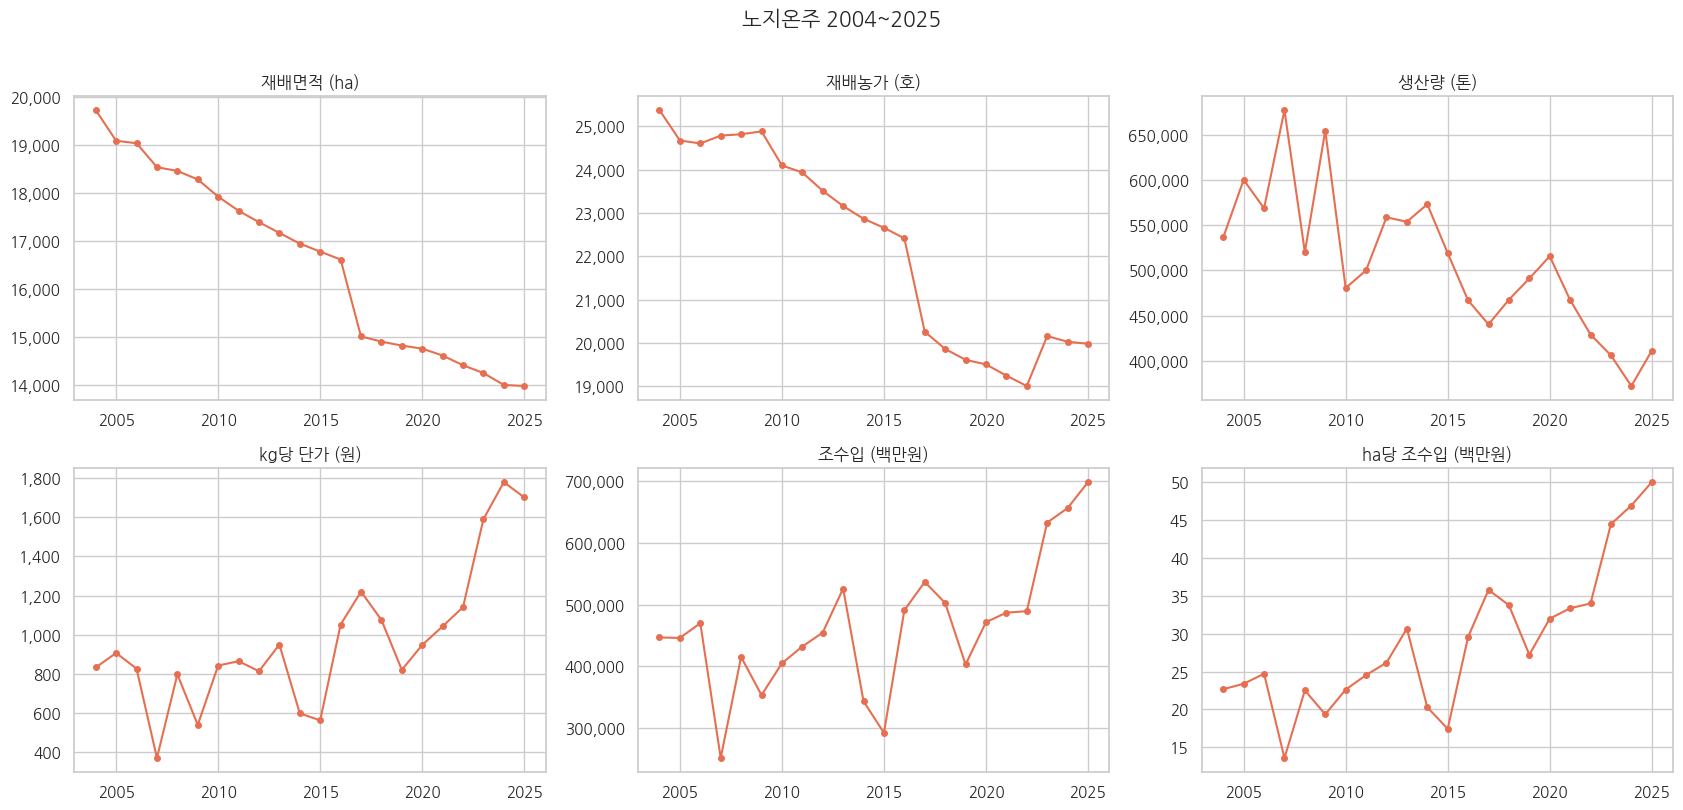

연도,2004,2025,변화율_퍼센트
재배면적_ha,"19,725.00","13,972.00",-29.17
재배농가_호,"25,374.00","19,983.00",-21.25
생산량_톤,"536,668.00","410,965.00",-23.42
단가_원_kg,833.00,"1,701.00",104.20
조수입_백만원,"447,062.00","698,979.00",56.35
ha당_조수입_백만원,22.66,50.03,120.73


In [2]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
specs = [
    ("재배면적_ha", "재배면적 (ha)"),
    ("재배농가_호", "재배농가 (호)"),
    ("생산량_톤", "생산량 (톤)"),
    ("단가_원_kg", "kg당 단가 (원)"),
    ("조수입_백만원", "조수입 (백만원)"),
    ("ha당_조수입_백만원", "ha당 조수입 (백만원)"),
]
for ax, (col, title) in zip(axes.flat, specs):
    ax.plot(noji.index, noji[col], marker="o", ms=4, color="#e76f51")
    ax.set_title(title)
    ax.yaxis.set_major_formatter(comma)
fig.suptitle("노지온주 2004~2025", fontsize=15, y=1.01)
fig.tight_layout()
savefig("02_noji_trend")
plt.show()

change = noji.loc[[2004, 2025], [c for c, _ in specs]].T
change["변화율_퍼센트"] = (change[2025] / change[2004] - 1) * 100
change

**📝 관찰**
- 재배면적은 **-29%**, 농가 수는 **-21%** 로 꾸준히 줄었습니다. 생산 기반이 축소되는 흐름입니다.
- 단가는 833원에서 1,701원으로 **약 2배**, ha당 조수입은 **약 2.2배**가 됐습니다. 면적이 줄어든 만큼 가격이 받쳐 주는 구조입니다.
- 단가는 2015년(563원)처럼 크게 떨어지는 해가 있을 만큼 **변동성이 큽니다**(변동계수 0.37).
- ⚠️ 물가 보정을 하지 않은 명목 가격입니다. 실질 가격 상승폭은 이보다 작습니다.

## 2. 품종별 ha당 조수입 (FR-204)

> ⚠️ **조수입 = 매출**입니다. 하우스 난방비, 시설 감가상각 같은 **경영비가 빠져 있어서 순수익 비교가 아닙니다.** 경영비 데이터를 확보하면 이 섹션을 보완합니다.

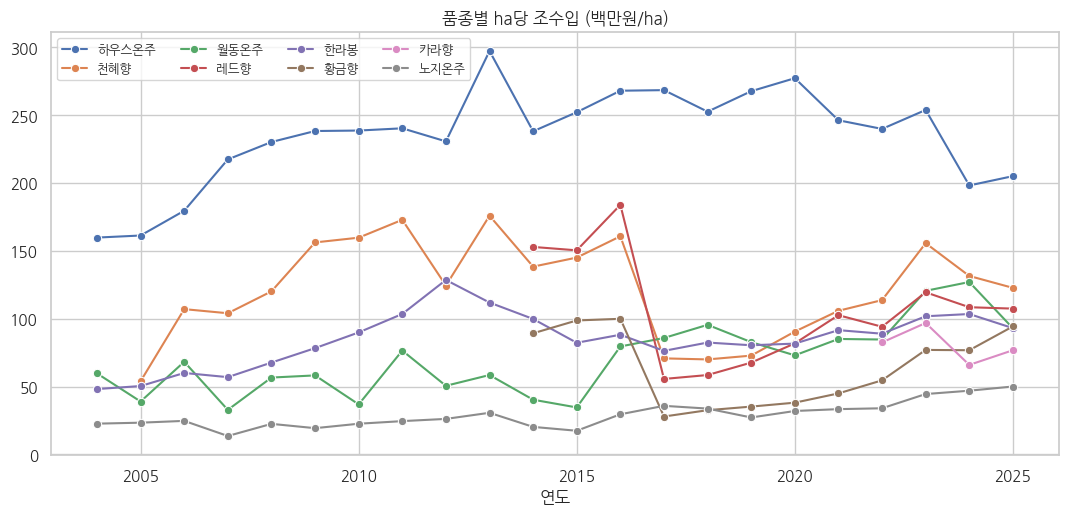

,2014~16 평균,2023~25 평균,노지온주 대비(배),10년 변화율_퍼센트
품종,,,,
하우스온주,252.67,218.95,4.64,-13.34
천혜향,148.01,136.58,2.90,-7.72
월동온주,51.48,113.48,2.41,120.45
레드향,162.34,111.75,2.37,-31.16
한라봉,90.07,99.41,2.11,10.37
황금향,95.94,82.67,1.75,-13.83
카라향,NaN,79.84,1.69,NaN
노지온주,22.42,47.15,1.00,110.24


In [3]:
order = (
    prod[prod["연도"] >= 2023].groupby("품종")["ha당_조수입_백만원"].mean().sort_values(ascending=False).index
)
fig, ax = plt.subplots(figsize=(13, 5.5))
sns.lineplot(data=prod, x="연도", y="ha당_조수입_백만원", hue="품종", hue_order=order, marker="o", ax=ax)
ax.set_title("품종별 ha당 조수입 (백만원/ha)")
ax.set_ylabel("")
ax.yaxis.set_major_formatter(comma)
ax.legend(ncol=4, fontsize=9)
savefig("02_revenue_per_ha")
plt.show()

pivot = prod.pivot_table(index="품종", columns="연도", values="ha당_조수입_백만원")
summary = pd.DataFrame(
    {
        "2014~16 평균": pivot[[2014, 2015, 2016]].mean(axis=1),
        "2023~25 평균": pivot[[2023, 2024, 2025]].mean(axis=1),
    }
)
summary["노지온주 대비(배)"] = summary["2023~25 평균"] / summary.loc["노지온주", "2023~25 평균"]
summary["10년 변화율_퍼센트"] = (summary["2023~25 평균"] / summary["2014~16 평균"] - 1) * 100
summary.loc[order]

In [4]:
# 데이터 점검: 황금향 재배면적 급증 (Q9)
prod[(prod["품종"] == "황금향") & prod["연도"].between(2015, 2019)][["연도", "재배면적_ha", "생산량_톤", "ha당_생산량_톤"]]

,연도,재배면적_ha,생산량_톤,ha당_생산량_톤
126,2015,76.00,2622,34.50
127,2016,98.10,3566,36.35
128,2017,351.00,3600,10.26
129,2018,353.00,3711,10.51
130,2019,352.00,4243,12.05


**📝 관찰**
- 최근 3년 평균으로 **하우스온주(2.19억 원/ha)가 노지의 4.6배**로 가장 높습니다. 그다음은 천혜향 2.9배, 월동온주와 레드향 2.4배입니다.
- 10년 사이에 **월동온주가 +120%로 가장 크게 올랐고**, **레드향은 -31%** 로 가장 크게 떨어졌습니다. 레드향은 재배가 빠르게 늘면서 단가가 내려간 것으로 보입니다.
- 노지온주도 10년 전보다 2.1배가 됐습니다. 품종 간 격차는 줄어드는 추세입니다.
- ⚠️ 황금향은 2016년에서 2017년 사이 재배면적이 98ha에서 351ha로 늘었는데 생산량은 그대로라서 ha당 지표가 급락합니다. 통계 기준이 바뀐 것으로 보이며, 황금향의 장기 비교는 신뢰하기 어렵습니다(Q9).

## 3. 생산량과 가격: 가격 탄력성

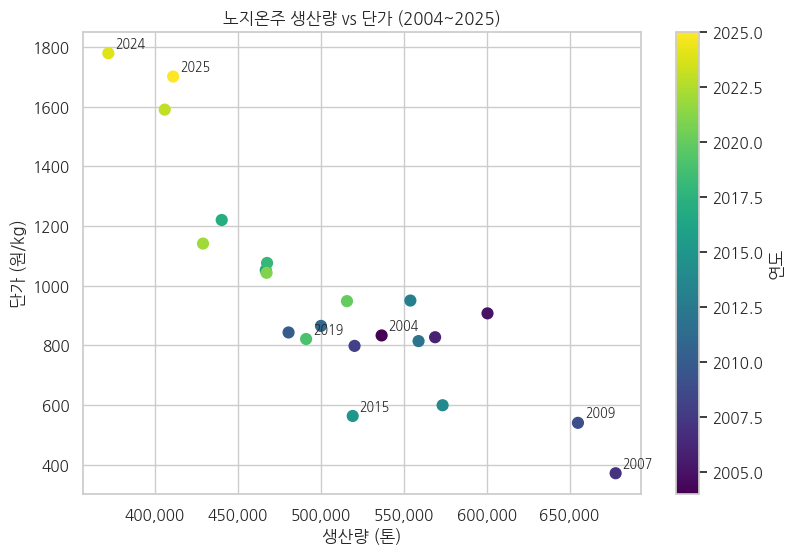

,상관계수,가격탄력성(log-log 기울기)
2004~2025,-0.86,-2.15
2015~2025,-0.94,-2.94


In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(noji["생산량_톤"], noji["단가_원_kg"], c=noji.index, cmap="viridis", s=60)
for y, r in noji.iterrows():
    if y in (2004, 2007, 2009, 2015, 2019, 2024, 2025):
        ax.annotate(y, (r["생산량_톤"], r["단가_원_kg"]), xytext=(5, 4), textcoords="offset points", fontsize=9)
plt.colorbar(sc, label="연도")
ax.xaxis.set_major_formatter(comma)
ax.set_xlabel("생산량 (톤)")
ax.set_ylabel("단가 (원/kg)")
ax.set_title("노지온주 생산량 vs 단가 (2004~2025)")
savefig("02_supply_price")
plt.show()


def elasticity(df):
    return np.polyfit(np.log(df["생산량_톤"]), np.log(df["단가_원_kg"]), 1)[0]


pd.DataFrame(
    {
        "상관계수": [noji["생산량_톤"].corr(noji["단가_원_kg"]), noji.loc[2015:, "생산량_톤"].corr(noji.loc[2015:, "단가_원_kg"])],
        "가격탄력성(log-log 기울기)": [elasticity(noji), elasticity(noji.loc[2015:])],
    },
    index=["2004~2025", "2015~2025"],
)

**📝 관찰**
- 생산량과 단가의 상관계수는 **-0.86**이고, 최근 10년은 **-0.94**로 더 강해졌습니다.
- 로그-로그 기울기로 계산한 가격 탄력성은 약 **-2.2**(최근 10년 **-2.9**)입니다. **생산량이 1% 늘면 단가가 2~3% 떨어진다**는 뜻입니다.
  - 그래서 **생산량이 늘어도 조수입은 오히려 줄 수 있습니다.** 2015년과 2019년처럼 많이 생산된 해에 조수입이 낮았던 이유입니다.
- 같은 생산량이어도 최근 연도(노란 점)일수록 가격이 높습니다. 물가 상승과 품질 향상이 더해진 효과로 보입니다.

## 4. 기상과 생산량·가격 (FR-203)

시즌 Y(Y년산)의 기상은 **같은 해 Y의 생육기 날씨**를 씁니다. 4개 관측지점(제주·고산·성산·서귀포)의 평균입니다.

> 폭염일수와 가격은 **둘 다 해마다 오르는 추세**라서, 그냥 상관을 구하면 관계가 부풀려집니다. 그래서 **연도 추세를 제거한 뒤의 상관**을 함께 봅니다.

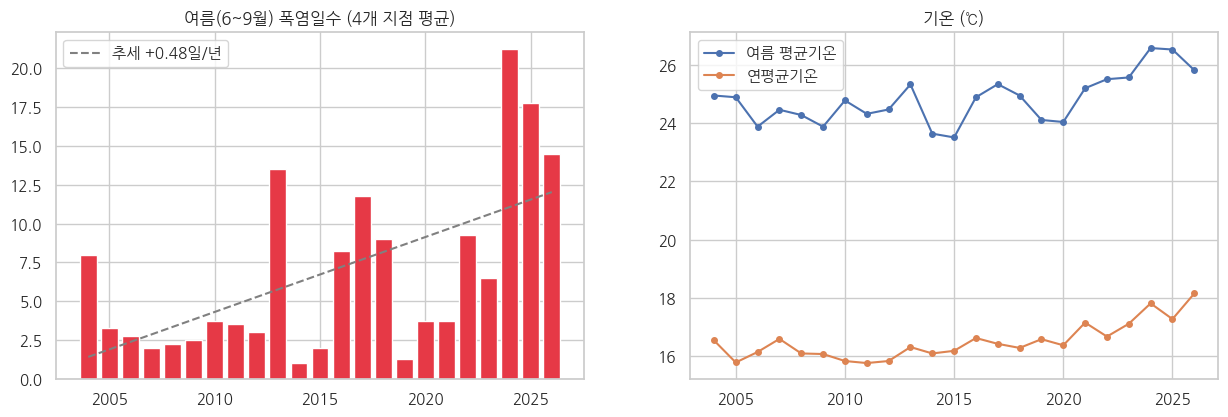

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(weather.index, weather["여름폭염일수"], color="#e63946")
axes[0].set_title("여름(6~9월) 폭염일수 (4개 지점 평균)")
z = np.polyfit(weather.index, weather["여름폭염일수"], 1)
axes[0].plot(weather.index, np.polyval(z, weather.index), "--", color="gray", label=f"추세 +{z[0]:.2f}일/년")
axes[0].legend()
axes[1].plot(weather.index, weather["여름평균기온_c"], marker="o", ms=4, label="여름 평균기온")
axes[1].plot(weather.index, weather["연평균기온_c"], marker="o", ms=4, label="연평균기온")
axes[1].set_title("기온 (℃)")
axes[1].legend()
savefig("02_weather_trend")
plt.show()

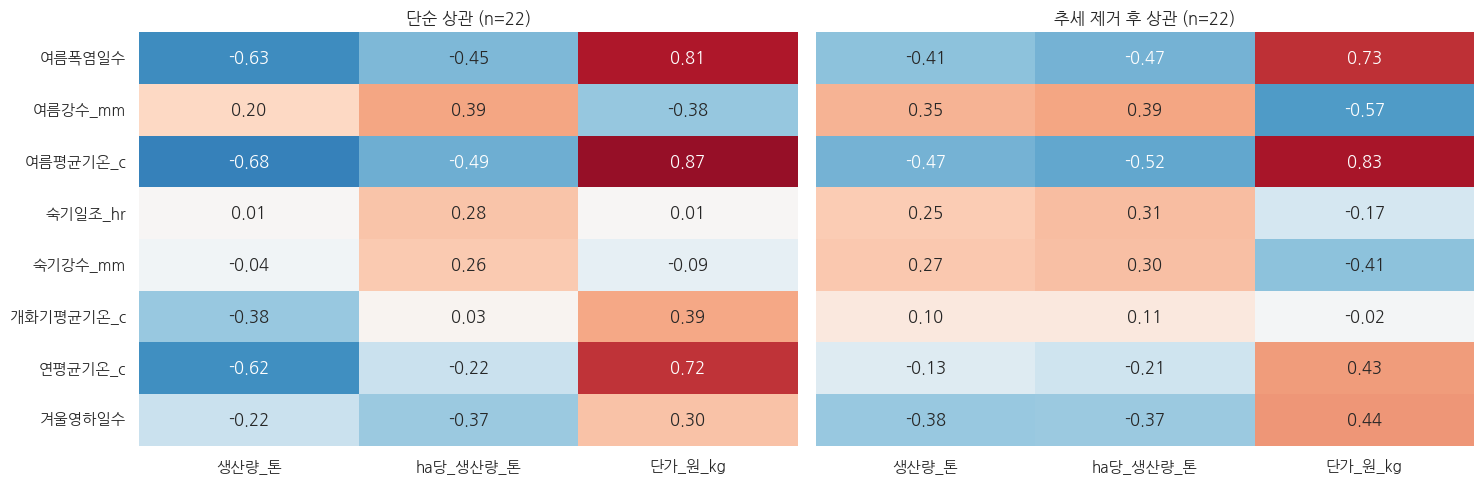

In [7]:
data = noji[["생산량_톤", "ha당_생산량_톤", "단가_원_kg"]].join(weather.drop(columns="관측월수"), how="inner")
years = data.index.values.astype(float)


def detrend(s):
    return s - np.polyval(np.polyfit(years, s, 1), years)


wcols = [c for c in weather.columns if c != "관측월수"]
targets = ["생산량_톤", "ha당_생산량_톤", "단가_원_kg"]
raw_corr = data.corr().loc[wcols, targets]
det_corr = data.apply(detrend).corr().loc[wcols, targets]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, mat, title in [(axes[0], raw_corr, "단순 상관"), (axes[1], det_corr, "추세 제거 후 상관")]:
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(f"{title} (n={len(data)})")
axes[1].tick_params(axis="y", left=False, labelleft=False)
fig.tight_layout()
savefig("02_weather_corr")
plt.show()

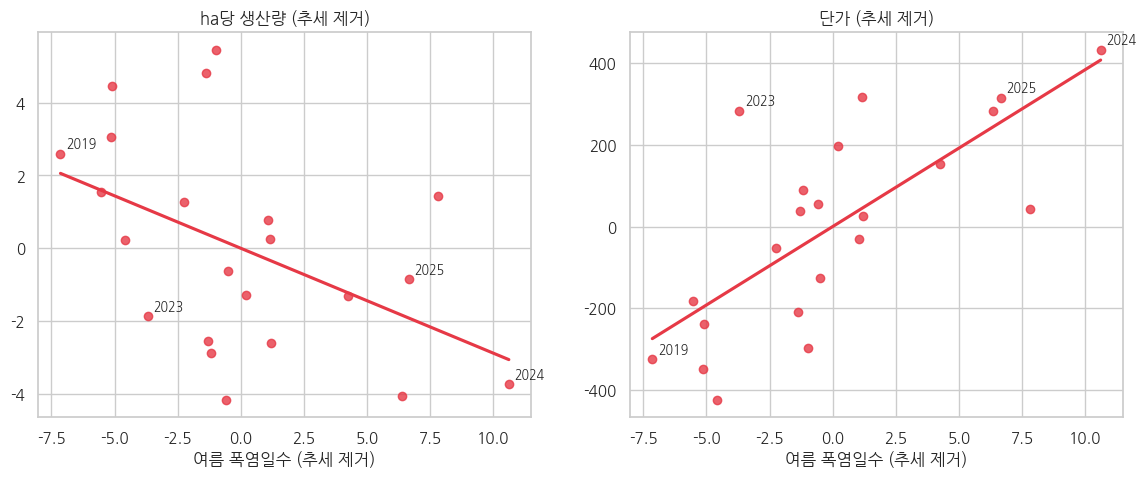

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
dt = data.apply(detrend)
for ax, col, title in [(axes[0], "ha당_생산량_톤", "ha당 생산량 (추세 제거)"), (axes[1], "단가_원_kg", "단가 (추세 제거)")]:
    sns.regplot(x=dt["여름폭염일수"], y=dt[col], ci=None, ax=ax, color="#e63946")
    for y in (2019, 2023, 2024, 2025):
        ax.annotate(y, (dt.loc[y, "여름폭염일수"], dt.loc[y, col]), xytext=(4, 4), textcoords="offset points", fontsize=9)
    ax.set_xlabel("여름 폭염일수 (추세 제거)")
    ax.set_ylabel("")
    ax.set_title(title)
plt.show()

**📝 관찰**
- 여름 폭염일수는 **해마다 약 0.45일씩 늘고 있습니다.** 2024년(21.2일)과 2025년(17.8일)은 관측 기간 중 가장 많았습니다.
- **폭염이 많은 해는 ha당 생산량이 적고(추세 제거 후 -0.47), 단가는 높았습니다(+0.73).** 생산량 감소가 가격 상승으로 이어지는 3절의 구조와 맞습니다.
- **여름 평균기온**은 폭염일수보다 관계가 더 강합니다(추세 제거 후 단가와 +0.83, ha당 생산량과 -0.52). 며칠의 극한 폭염보다 **여름 전체가 얼마나 더웠는지**가 더 중요할 수 있습니다.
- 여름 강수량이 많은 해는 단가가 낮았습니다(추세 제거 후 -0.57). 비가 많고 덜 더운 여름일수록 생산이 잘 되는 것으로 보입니다.
- 숙기(9~11월) 일조량과 강수량은 생산량과의 관계가 약했습니다. 품질(당도)에는 영향이 있을 수 있지만, 품질 데이터가 없어서 확인할 수 없습니다.
- ⚠️ 표본이 22개이고, 상관관계가 곧 인과관계는 아닙니다. 폭염이 직접 생산량을 줄였는지, 같은 시기의 다른 요인(병해충, 해거리 등) 때문인지는 이 데이터로 구분할 수 없습니다.

## 5. 2026년산 가격 방향 (FR-303 시험)

**간단한 회귀 모델**로 방향만 가늠해 봅니다.
- 모델 A: `log(단가) = 연도 추세 + 여름폭염일수`. 2026년의 여름 날씨는 이미 확정이라 **지금 바로 예측할 수 있습니다.**
- 모델 B: `log(단가) = 연도 추세 + log(생산량)`. **그해 실제 생산량**을 넣으므로, 관측 발표 후에만 쓸 수 있는 '생산량을 알 때' 시나리오입니다.

**검증 방법 — 확장 윈도우 백테스트**
- 2015~2025년의 각 연도를 **그 이전 연도 데이터로만** 학습해서 예측합니다. 실제로 예측할 때와 같은 조건입니다.
  - 처음 작성한 Leave-One-Out은 미래 연도까지 학습에 써서 오차가 낙관적으로 나옵니다. 그래서 이 방법으로 바꿨습니다.
- **기준선은 '전년 단가 그대로'입니다.** 모델이 이 기준선보다 나아야 쓸 의미가 있습니다.
- 지표는 평균 오차율(MAPE)입니다. MAPE는 **평균적으로 얼마나 빗나갔는지**를 뜻하는 값이고, 신뢰구간이 아닙니다.

In [9]:
model_df = data.assign(연도c=data.index - 2015, ln생산량=np.log(data["생산량_톤"]))
BACKTEST_YEARS = range(2015, 2026)  # 첫 학습 구간: 2004~2014 (11년)


def fit(X, y):
    X1 = np.column_stack([np.ones(len(X)), X])
    return np.linalg.lstsq(X1, y, rcond=None)[0]


def predict(cols, train, test):
    """train으로 log(단가) 회귀를 학습해 test 연도의 단가를 예측합니다."""
    b = fit(train[cols].values, np.log(train["단가_원_kg"].values))
    return float(np.exp(b[0] + test[cols].values @ b[1:]))


def backtest_errors(cols):
    """확장 윈도우: 각 연도를 그 이전 연도로만 학습해 예측한 오차율(절대값) 목록."""
    errs = {}
    for yr in BACKTEST_YEARS:
        actual = model_df.loc[yr, "단가_원_kg"]
        pred = model_df.loc[yr - 1, "단가_원_kg"] if cols is None else predict(cols, model_df.loc[: yr - 1], model_df.loc[yr])
        errs[yr] = abs(pred / actual - 1)
    return pd.Series(errs)


models = {
    "기준선: 전년 단가 그대로": None,
    "추세만": ["연도c"],
    "A: 추세 + 폭염": ["연도c", "여름폭염일수"],
    "B: 추세 + 생산량 (생산량을 알 때)": ["연도c", "ln생산량"],
    "추세 + 생산량 + 폭염": ["연도c", "ln생산량", "여름폭염일수"],
    "(참고) 추세 + 여름평균기온 *": ["연도c", "여름평균기온_c"],
}
errors = pd.DataFrame({k: backtest_errors(v) for k, v in models.items()})
backtest = pd.DataFrame(
    {
        "평균 오차율_퍼센트": errors.mean() * 100,
        "최대 오차율_퍼센트": errors.max() * 100,
        "기준선보다 나은 연도 수": (errors.lt(errors["기준선: 전년 단가 그대로"], axis=0)).sum().astype(str) + f" / {len(errors)}",
    }
)
backtest.loc["기준선: 전년 단가 그대로", "기준선보다 나은 연도 수"] = "-"
print(f"확장 윈도우 백테스트 {min(BACKTEST_YEARS)}~{max(BACKTEST_YEARS)}년 ({len(errors)}개 연도)")
print("* 여름평균기온은 4절 상관분석에서 가장 강했던 변수를 보고 고른 것이라 결과가 낙관적입니다.")
backtest.round(1)

확장 윈도우 백테스트 2015~2025년 (11개 연도)
* 여름평균기온은 4절 상관분석에서 가장 강했던 변수를 보고 고른 것이라 결과가 낙관적입니다.


,평균 오차율_퍼센트,최대 오차율_퍼센트,기준선보다 나은 연도 수
기준선: 전년 단가 그대로,16.90,46.50,-
추세만,22.80,36.80,4 / 11
A: 추세 + 폭염,16.10,34.50,5 / 11
B: 추세 + 생산량 (생산량을 알 때),15.60,44.10,7 / 11
추세 + 생산량 + 폭염,15.10,33.20,5 / 11
(참고) 추세 + 여름평균기온 *,11.60,18.00,6 / 11


In [10]:
cols = models["A: 추세 + 폭염"]
x2026 = pd.DataFrame({"연도c": [2026 - 2015], "여름폭염일수": [weather.loc[2026, "여름폭염일수"]]}).iloc[0]
pred_2026 = predict(cols, model_df, x2026)
mape_a = errors["A: 추세 + 폭염"].mean()
mape_naive = errors["기준선: 전년 단가 그대로"].mean()

print(f"2026 여름 폭염일수 : {weather.loc[2026, '여름폭염일수']:.1f}일 (2024: {weather.loc[2024, '여름폭염일수']:.1f}, 2025: {weather.loc[2025, '여름폭염일수']:.1f})")
print(f"2025년산 실제 단가 : {noji.loc[2025, '단가_원_kg']:,.0f}원/kg  (= 기준선의 2026년산 예측)")
print(f"2026년산 모델 A 예측: {pred_2026:,.0f}원/kg  (전년 대비 {pred_2026 / noji.loc[2025, '단가_원_kg'] - 1:+.1%})")
print(f"백테스트 평균 오차율: 모델 A {mape_a:.1%} vs 기준선 {mape_naive:.1%}  (최대 오차 {errors['A: 추세 + 폭염'].max():.0%})")

2026 여름 폭염일수 : 14.5일 (2024: 21.2, 2025: 17.8)
2025년산 실제 단가 : 1,701원/kg  (= 기준선의 2026년산 예측)
2026년산 모델 A 예측: 1,580원/kg  (전년 대비 -7.1%)
백테스트 평균 오차율: 모델 A 16.1% vs 기준선 16.9%  (최대 오차 34%)


In [11]:
# 실제 시장 신호: 시즌 초반(9/1 ~ 11/8) 도매가격·출하량을 시즌별로 비교
md_str = daily["일자"].dt.strftime("%m-%d")
early = daily[(md_str >= "09-01") & (md_str <= "11-08")].dropna(subset=["도매_평균가_원_5kg"])
early = early[early["도매_출하량_톤"] > 0]
early_summary = early.groupby("시즌").apply(
    lambda x: pd.Series(
        {
            "도매 가중평균가_원_5kg": np.average(x["도매_평균가_원_5kg"], weights=x["도매_출하량_톤"]),
            "총 출하량_톤": x["합계_출하량_톤"].sum(),
        }
    ),
    include_groups=False,
)
early_summary["가격 전년비_퍼센트"] = early_summary["도매 가중평균가_원_5kg"].pct_change() * 100
early_summary["출하량 전년비_퍼센트"] = early_summary["총 출하량_톤"].pct_change() * 100
early_summary

,도매 가중평균가_원_5kg,총 출하량_톤,가격 전년비_퍼센트,출하량 전년비_퍼센트
시즌,,,,
2021,"7,572.17","35,286.50",NaN,NaN
2022,"7,891.69","36,533.40",4.22,3.53
2023,"9,403.56","40,879.40",19.16,11.90
2024,"9,283.55","32,583.30",-1.28,-20.29
2025,"10,212.93","28,723.70",10.01,-11.85
2026,"9,454.31","38,149.90",-7.43,32.82


**📝 관찰**
- **모델 A(추세 + 폭염)는 기준선 '전년 단가 그대로'와 거의 차이가 없습니다.** 평균 오차율은 16.1%와 16.9%이고, 11개 연도 중 기준선보다 나았던 해는 5개뿐입니다.
  - 4절에서 본 폭염과 단가의 상관은 **연간 단가를 예측하는 힘으로 이어지지 않았습니다.**
- 생산량을 직접 넣은 모델 B도 15.6%로 조금 나은 정도입니다. 생산량과 가격의 관계는 뚜렷하지만(3절), 해마다 가격 변동이 크고 학습 기간이 짧아서 연도별 예측은 어렵습니다.
- 여름평균기온 모델이 11.6%로 가장 좋습니다. 다만 상관분석 결과를 보고 고른 변수라서, 새로운 연도(2026년산 이후)에서 다시 검증하기 전에는 믿을 수 없습니다.
- 모델 A의 2026년산 예측은 **1,580원/kg(전년 대비 -7%)** 입니다. 모델이 기준선보다 낫지 않으므로 **이 숫자만으로는 근거가 되지 않습니다.**
- **현재 가장 직접적인 근거는 시장 신호입니다.** 시즌 초반(9월 1일 ~ 11월 8일)을 비교한 결과는 다음과 같습니다.
  - 2026 시즌 출하량은 2025 시즌보다 **약 33% 많고**, 도매 가중평균가는 **약 7% 낮습니다.**
  - 아직 시즌 초반이라 12~2월 본격 출하 가격은 다를 수 있습니다.
  - 2021 시즌은 일별 데이터가 10월 1일부터 있어서 9월이 빠져 있습니다.
- **정리:** 2026년산은 "약보합 가능성이 있다" 정도로만 말할 수 있고, 근거는 시장 신호입니다.
- ⚠️ 연간 단가 자체에 정의 문제(Q8)가 있습니다. 에이전트에 넣을 때는 **예측값과 함께 '기준선 대비 성능'을 반드시 제시**해야 합니다.

## 6. 출하 시기: 언제 팔면 비싼가?

일별 가격(2021~2026 시즌)으로 월별 **출하량 가중평균 도매가격**을 봅니다. 일요일과 휴장일은 가격이 없어서 제외합니다.

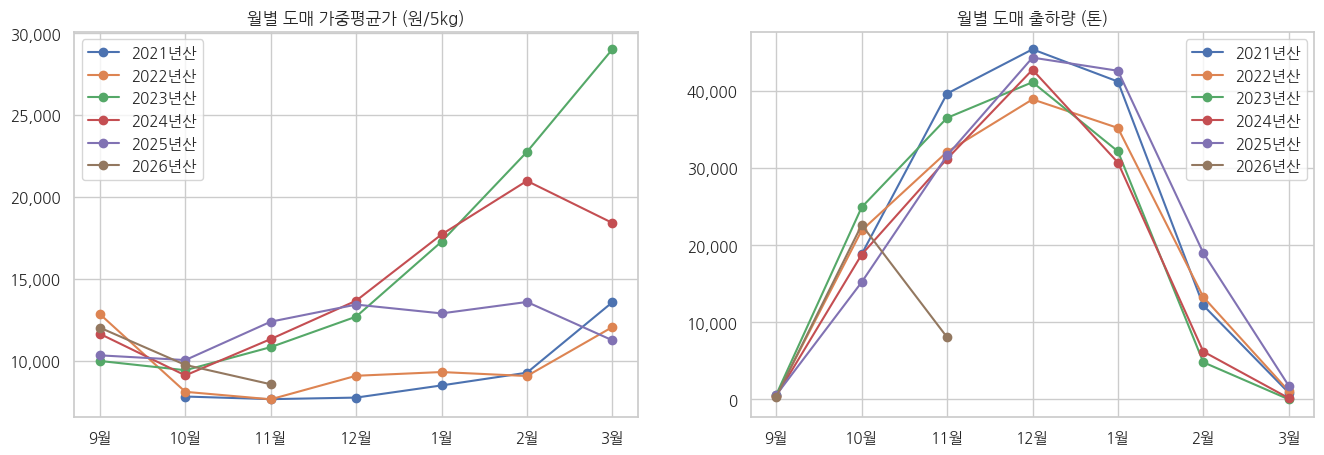

월,9,10,11,12,1,2,3
시즌,,,,,,,
2021,-,"7,803","7,643","7,738","8,481","9,259","13,559"
2022,"12,831","8,091","7,634","9,071","9,299","9,056","12,044"
2023,"9,975","9,410","10,820","12,681","17,261","22,743","29,009"
2024,"11,630","9,093","11,313","13,655","17,700","20,974","18,406"
2025,"10,318","10,030","12,375","13,418","12,880","13,578","11,238"
2026,"12,007","9,734","8,552",-,-,-,-


In [12]:
mp = monthly_weighted_price(daily)
month_order = [9, 10, 11, 12, 1, 2, 3]
price_tbl = mp.pivot(index="시즌", columns="월", values="가중평균가").reindex(columns=month_order)
vol_tbl = mp.pivot(index="시즌", columns="월", values="출하량_톤").reindex(columns=month_order)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
labels = [f"{m}월" for m in month_order]
for season, row in price_tbl.iterrows():
    axes[0].plot(labels, row.values, marker="o", label=f"{season}년산")
axes[0].set_title("월별 도매 가중평균가 (원/5kg)")
axes[0].yaxis.set_major_formatter(comma)
axes[0].legend()
for season, row in vol_tbl.iterrows():
    axes[1].plot(labels, row.values, marker="o", label=f"{season}년산")
axes[1].set_title("월별 도매 출하량 (톤)")
axes[1].yaxis.set_major_formatter(comma)
axes[1].legend()
savefig("02_monthly_price_by_season")
plt.show()

price_tbl.style.format("{:,.0f}", na_rep="-")

In [13]:
# 12월 대비 가격 배수 + 그해 생산량
ratio = price_tbl[[10, 11, 12, 1, 2]].div(price_tbl[12], axis=0)
ratio.columns = [f"{m}월/12월" for m in ratio.columns]
ratio = ratio.join(noji["생산량_톤"]).dropna(subset=["2월/12월"])
print(f"2월 프리미엄과 생산량의 상관계수: {ratio['2월/12월'].corr(ratio['생산량_톤']):.2f} (n={len(ratio)}, 판단 근거로 쓰기 어려움)")

# 생산량이 거의 같았던 두 해 비교
a, b = ratio.loc[2023], ratio.loc[2025]
print(
    f"2023년산 vs 2025년산: 생산량 {a['생산량_톤']:,.0f}톤 vs {b['생산량_톤']:,.0f}톤 "
    f"(차이 {b['생산량_톤'] / a['생산량_톤'] - 1:+.1%}) → 2월/12월 {a['2월/12월']:.2f}배 vs {b['2월/12월']:.2f}배"
)
ratio.style.format({c: "{:.2f}" for c in ratio.columns if "월" in c} | {"생산량_톤": "{:,.0f}"})

2월 프리미엄과 생산량의 상관계수: -0.48 (n=5, 판단 근거로 쓰기 어려움)
2023년산 vs 2025년산: 생산량 405,885톤 vs 410,965톤 (차이 +1.3%) → 2월/12월 1.79배 vs 1.01배


,10월/12월,11월/12월,12월/12월,1월/12월,2월/12월,생산량_톤
시즌,,,,,,
2021,1.01,0.99,1.00,1.10,1.20,"467,293"
2022,0.89,0.84,1.00,1.03,1.00,"428,977"
2023,0.74,0.85,1.00,1.36,1.79,"405,885"
2024,0.67,0.83,1.00,1.30,1.54,"371,916"
2025,0.75,0.92,1.00,0.96,1.01,"410,965"


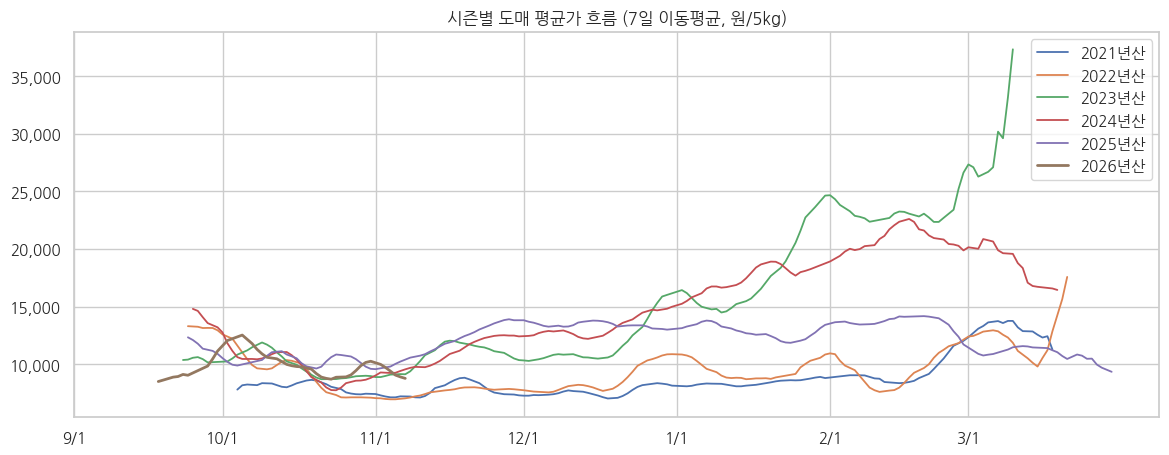

In [14]:
# 시즌 내 일별 흐름 (7일 이동평균)
d = daily.dropna(subset=["도매_평균가_원_5kg"]).copy()
season_start = pd.to_datetime(d["시즌"].astype(str) + "-09-01")
d["시즌경과일"] = (d["일자"] - season_start).dt.days
d = d.sort_values(["시즌", "일자"])
d["7일평균가"] = d.groupby("시즌")["도매_평균가_원_5kg"].transform(lambda s: s.rolling(7, min_periods=3).mean())

fig, ax = plt.subplots(figsize=(14, 5))
for season, g in d[d["시즌경과일"] <= 210].groupby("시즌"):
    ax.plot(g["시즌경과일"], g["7일평균가"], label=f"{season}년산", lw=2 if season == 2026 else 1.3)
ticks = {0: "9/1", 30: "10/1", 61: "11/1", 91: "12/1", 122: "1/1", 153: "2/1", 181: "3/1"}
ax.set_xticks(list(ticks), list(ticks.values()))
ax.yaxis.set_major_formatter(comma)
ax.set_title("시즌별 도매 평균가 흐름 (7일 이동평균, 원/5kg)")
ax.legend()
savefig("02_daily_price_flow")
plt.show()

**📝 관찰**
- **"늦게 팔수록 비싸다"는 해마다 달랐습니다.**
  - 2023년과 2024년산은 12월 대비 2월 가격이 **1.8배, 1.5배**로 크게 올랐습니다.
  - 2021년, 2022년, 2025년산은 1.0~1.2배로 거의 오르지 않았습니다.
- **이 차이는 생산량으로 설명되지 않습니다.** 2023년산과 2025년산은 생산량이 거의 같았는데(40.6만 톤 vs 41.1만 톤, +1.3%), 2월 프리미엄은 1.79배와 1.01배로 완전히 달랐습니다.
  - 생산량과 2월 프리미엄의 상관계수(-0.48)는 시즌이 5개뿐이라 판단 근거로 쓸 수 없습니다.
  - 후보 요인(가설): 과실 품질·저장성, 시즌 중 출하량 배분, 같은 시기 만감류·수입 과일 공급. 지금 데이터로는 확인할 수 없습니다.
- 10월 가격은 해마다 12월의 0.67~1.01배로, **조기 출하는 대체로 불리**합니다. 다섯 시즌 모두 같은 방향이라 비교적 일관된 결과입니다.
- 출하량은 매년 **12월이 정점**이고, 2월 이후 급감합니다. 늦게 팔 수 있는 물량에는 저장 능력과 품질 유지라는 제약이 있습니다.
- 3월 이후의 급등(예: 2023년산 3만 원대)은 **출하량이 매우 적은 시기의 가격**이라 대표성이 낮습니다.
- **에이전트 응답 원칙:** "언제 팔면 좋아?"라는 질문에는 다음처럼 답해야 합니다.
  - "조기 출하(10월)는 대체로 불리하다"는 말할 수 있습니다.
  - 저장 후 늦은 출하의 이득은 **해마다 크게 달랐고(1.0~1.8배), 원인은 아직 모른다**고 답합니다.
  - 시즌 중에는 12월 이후의 실제 가격 흐름을 보고 판단하도록 안내합니다.

## 7. 정리

### 에이전트가 근거를 갖고 말할 수 있게 된 것
| 질문 유형 | 근거 | 신뢰도 |
| --- | --- | --- |
| 생산량이 늘면 가격은? | 22년, 탄력성 -2.2 ~ -2.9 | 🟢 높음 |
| 품종별 면적당 매출 | 8개 품종 × 최대 22년 | 🟢 높음 (매출 한정) |
| 여름 더위(폭염·평균기온)와 생산량·가격 | 22년, 추세 제거 후 상관 | 🟡 중간 (상관, n=22) |
| 2026년산 가격 방향 | 시즌 초반 실측 (모델 A는 기준선 수준) | 🟡 방향만, 시장 신호 근거 |
| 조기 출하(10월)는 불리한가? | 5개 시즌 일별 가격, 모두 같은 방향 | 🟡 중간 |
| 저장 후 늦은 출하(2월)는 유리한가? | 5개 시즌 일별 가격, 1.0~1.8배로 제각각 | 🔴 낮음 (원인 미확인) |

### 남은 한계 → 다음 할 일
- [ ] **경영비** 데이터가 없어서 순수익 비교는 불가능 → 필요 시 농산물소득자료집 확보
- [ ] **물가 보정** 전 명목 가격 → CPI 확보 시 실질 가격으로 재계산
- [ ] 단가 정의(Q8), 황금향 통계 단절(Q9) → 해당 연도 분석 제외 또는 출처 문의
- [ ] **예측 모델이 기준선('전년 단가 그대로')을 넘지 못함** → 출하량·가격의 시즌 중 실측값을 쓰는 모델 검토, 여름평균기온 모델은 2026년산 실적으로 재검증
- [ ] **2월 프리미엄의 원인** 조사 → 시즌별 출하량 배분, 만감류 출하 시기, 품질 지표 확보
- [ ] 모델 A·B를 `src/jeju_citrus/models/`로 옮겨서 에이전트가 호출할 수 있게 만들기
- [ ] **에이전트 v0 설계**: 위 표의 질문 유형별로 데이터 조회 → 수치 근거 → 답변 템플릿